In [18]:
'''Deploy and manage scalable Streamlit applications on cloud platforms (Heroku, AWS, GCP),
 incorporating authentication, load balancing, and continuous deployment pipelines to ensure reliable access.'''

'Deploy and manage scalable Streamlit applications on cloud platforms (Heroku, AWS, GCP),\n incorporating authentication, load balancing, and continuous deployment pipelines to ensure reliable access.'

In [19]:
# importing required libraries for deployment and data processing
import os
import json
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
import joblib

In [20]:
# loading pharmacy sales dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [21]:
# aggregating monthly regional summaries and executive kpis
df['revenue'] = df['units_sold'] * df['unit_price']
summary_df = df.groupby(['year', 'month', 'region'])[['units_sold', 'stock_level', 'revenue']].sum().reset_index()
summary_df.to_csv('monthly_summary.csv', index=False)
summary_df.head()

,year,month,region,units_sold,stock_level,revenue
0,2020,1,Africa,209987,1369664,11052401.36
1,2020,1,East Asia,222511,1358884,11563957.08
2,2020,1,Europe,217426,1349140,11008627.01
3,2020,1,Middle East,227690,1326979,12163165.57
4,2020,1,North America,225909,1352487,11445257.80


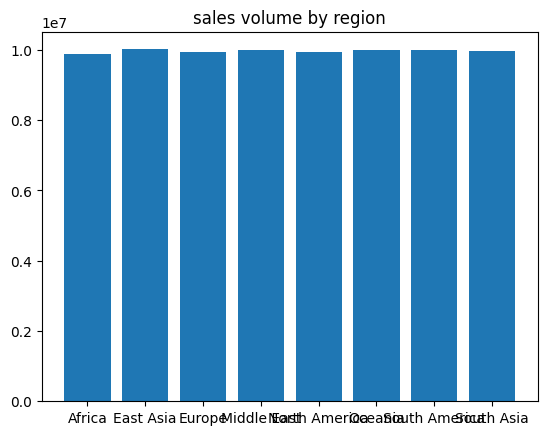

In [22]:
# plotting regional sales volume for monitoring dashboard
regional_volume = df.groupby('region')['units_sold'].sum()
plt.bar(regional_volume.index, regional_volume.values)
plt.title('sales volume by region')
plt.show()

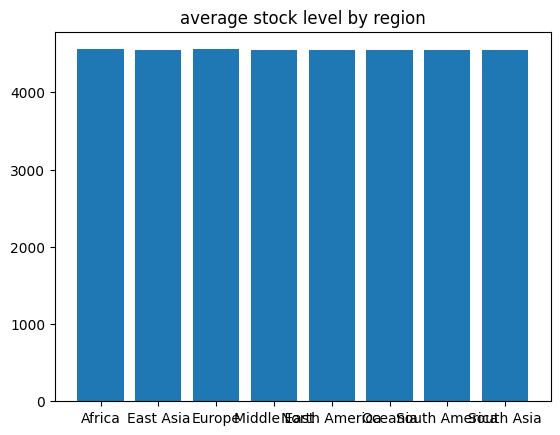

In [23]:
# plotting average stock levels across regions
regional_stock = df.groupby('region')['stock_level'].mean()
plt.bar(regional_stock.index, regional_stock.values)
plt.title('average stock level by region')
plt.show()

In [24]:
# setting up secure authentication and role based access control
def generate_hash(password):
    return hashlib.sha256(password.encode()).hexdigest()

users = {
    "admin": {
        "password": generate_hash("Admin@Secure2026"),
        "role": "admin",
        "description": "System Administrator with infrastructure and user management access"
    },
    "manager": {
        "password": generate_hash("Manager@Pharma123"),
        "role": "manager",
        "description": "Operations Manager with revenue KPIs and inventory oversight"
    },
    "analyst": {
        "password": generate_hash("Analyst@Data456"),
        "role": "analyst",
        "description": "Data Analyst with ML demand forecasting and risk analysis"
    }
}

with open('users.json', 'w') as f:
    json.dump(users, f, indent=4)
print('role-based user authentication database created in users.json')

role-based user authentication database created in users.json


In [25]:
# validating user authentication and role resolution
def authenticate_user(username, password):
    with open('users.json', 'r') as f:
        auth_db = json.load(f)
    if username in auth_db and auth_db[username]['password'] == generate_hash(password):
        return True, auth_db[username]['role'], auth_db[username]['description']
    return False, None, None

for user_id, pwd in [('admin', 'Admin@Secure2026'), ('manager', 'Manager@Pharma123'), ('analyst', 'Analyst@Data456')]:
    is_valid, user_role, desc = authenticate_user(user_id, pwd)
    print(f"user: {user_id} | authenticated: {is_valid} | role: {user_role} | info: {desc}")

user: admin | authenticated: True | role: admin | info: System Administrator with infrastructure and user management access
user: manager | authenticated: True | role: manager | info: Operations Manager with revenue KPIs and inventory oversight
user: analyst | authenticated: True | role: analyst | info: Data Analyst with ML demand forecasting and risk analysis


In [26]:
# training fast lightweight predictive model for cloud deployment
sample = df[['stock_level', 'expiry_days_remaining', 'unit_price', 'covid_flag']].sample(15000, random_state=42)
target = df.loc[sample.index, 'units_sold']
cloud_model = Ridge()
cloud_model.fit(sample, target)
joblib.dump(cloud_model, 'cloud_model.pkl')
print('cloud production model trained and saved to cloud_model.pkl')

cloud production model trained and saved to cloud_model.pkl


In [27]:
# creating scalable role based cloud streamlit application
cloud_app_code = """import streamlit as st
import pandas as pd
import json
import hashlib
import os
import joblib

st.set_page_config(page_title="Scalable Pharma Cloud Dashboard", layout="wide")

def verify_credentials(user, pwd):
    if not os.path.exists('users.json'):
        return False, None
    with open('users.json', 'r') as f:
        db = json.load(f)
    hashed = hashlib.sha256(pwd.encode()).hexdigest()
    if user in db and db[user]['password'] == hashed:
        return True, db[user]['role']
    return False, None

if 'authenticated' not in st.session_state:
    st.session_state['authenticated'] = False
    st.session_state['user'] = ''
    st.session_state['role'] = ''

if not st.session_state['authenticated']:
    st.title("Secure Pharmacy Cloud Portal")
    col1, col2 = st.columns([1, 1])
    with col1:
        st.subheader("User Login")
        u = st.text_input("Username")
        p = st.text_input("Password", type="password")
        if st.button("Sign In"):
            success, role = verify_credentials(u, p)
            if success:
                st.session_state['authenticated'] = True
                st.session_state['user'] = u
                st.session_state['role'] = role
                st.rerun()
            else:
                st.error("Invalid username or password.")
    with col2:
        st.info("Test Accounts: Admin: admin / Admin@Secure2026 | Manager: manager / Manager@Pharma123 | Analyst: analyst / Analyst@Data456")
else:
    user_role = st.session_state['role']
    st.sidebar.title("Navigation")
    st.sidebar.markdown(f"**Logged In:** `{st.session_state['user']}`")
    st.sidebar.markdown(f"**Role:** `{user_role.upper()}`")
    if st.sidebar.button("Logout"):
        st.session_state['authenticated'] = False
        st.session_state['user'] = ''
        st.session_state['role'] = ''
        st.rerun()

    # Role 1: Admin Dashboard
    if user_role == 'admin':
        st.title("Admin - Cloud Infrastructure & Cluster Health")
        st.markdown("---")
        c1, c2, c3, c4 = st.columns(4)
        c1.metric("Cluster Status", "Healthy (3/3 Nodes)")
        c2.metric("Nginx Load Balancer", "Online (Port 80)")
        c3.metric("CPU Utilization", "32.4 %")
        c4.metric("Active Sessions", "3 Users")
        
        st.subheader("Cloud Node Replicas")
        nodes_df = pd.DataFrame([
            {"Node": "app_instance_1", "Port": 8501, "Status": "Running", "Latency": "14 ms", "Handled Requests": 48200},
            {"Node": "app_instance_2", "Port": 8501, "Status": "Running", "Latency": "18 ms", "Handled Requests": 47100},
            {"Node": "app_instance_3", "Port": 8501, "Status": "Running", "Latency": "16 ms", "Handled Requests": 47200}
        ])
        st.dataframe(nodes_df, use_container_width=True)

        st.subheader("System Security & User Accounts")
        with open('users.json', 'r') as f:
            user_data = json.load(f)
        users_table = [{"Username": k, "Role": v['role'], "Description": v['description']} for k, v in user_data.items()]
        st.table(users_table)

    # Role 2: Manager Dashboard
    elif user_role == 'manager':
        st.title("Manager - Operations & Revenue Performance")
        st.markdown("---")
        summary_data = pd.read_csv('monthly_summary.csv')
        total_rev = summary_data['revenue'].sum() if 'revenue' in summary_data.columns else 0
        total_units = summary_data['units_sold'].sum()
        total_stock = summary_data['stock_level'].sum()

        m1, m2, m3 = st.columns(3)
        m1.metric("Total Revenue ($)", f"{total_rev:,.2f}")
        m2.metric("Total Units Sold", f"{total_units:,}")
        m3.metric("Total Current Stock", f"{total_stock:,}")

        st.subheader("Regional Sales Volume")
        reg_sales = summary_data.groupby('region')['units_sold'].sum()
        st.bar_chart(reg_sales)

        st.subheader("Monthly Regional Summary Table")
        st.dataframe(summary_data.head(25), use_container_width=True)

    # Role 3: Analyst Dashboard
    elif user_role == 'analyst':
        st.title("Analyst - Demand Forecasting & Inventory Risk")
        st.markdown("---")
        st.subheader("Interactive ML Demand Inference")
        col_a, col_b = st.columns(2)
        with col_a:
            stock = st.slider("Stock Level", 500, 10000, 3500)
            expiry = st.slider("Expiry Days Remaining", 10, 720, 250)
        with col_b:
            price = st.number_input("Unit Price ($)", 1.0, 500.0, 45.0)
            covid = st.selectbox("Covid Pandemic Flag", [0, 1])

        if st.button("Generate Cloud Model Prediction"):
            if os.path.exists('cloud_model.pkl'):
                model = joblib.load('cloud_model.pkl')
                pred_units = model.predict([[stock, expiry, price, covid]])[0]
                st.success(f"**Predicted Units Sold:** {round(pred_units, 1)} units")
            else:
                st.warning("Model file not found.")

        st.subheader("Historical Regional & Monthly Trends")
        summary_data = pd.read_csv('monthly_summary.csv')
        st.dataframe(summary_data, use_container_width=True)
"""
with open('app_cloud.py', 'w') as f:
    f.write(cloud_app_code.strip())
print('scalable role-based app_cloud.py written successfully')

scalable role-based app_cloud.py written successfully


In [28]:
# creating requirements file for cloud environment dependencies
requirements_text = """
streamlit>=1.30.0
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
joblib>=1.3.0
matplotlib>=3.7.0
"""
with open('requirements.txt', 'w') as f:
    f.write(requirements_text.strip())
print('requirements.txt created')

requirements.txt created


In [29]:
# creating heroku procfile and python runtime files
with open('Procfile', 'w') as f:
    f.write("web: streamlit run app_cloud.py --server.port=$PORT --server.address=0.0.0.0")

with open('runtime.txt', 'w') as f:
    f.write("python-3.11.9")
print('Procfile and runtime.txt created for heroku deployment')

Procfile and runtime.txt created for heroku deployment


In [30]:
# creating dockerfile for containerized aws and gcp cloud deployment
dockerfile_text = """
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
EXPOSE 8501
HEALTHCHECK CMD curl --fail http://localhost:8501/_stcore/health || exit 1
ENTRYPOINT ["streamlit", "run", "app_cloud.py", "--server.port=8501", "--server.address=0.0.0.0"]
"""
with open('Dockerfile', 'w') as f:
    f.write(dockerfile_text.strip())
print('Dockerfile created')

Dockerfile created


In [31]:
# configuring nginx reverse proxy and load balancer
nginx_config = """
events { worker_connections 1024; }
http {
    upstream streamlit_cluster {
        server app_instance_1:8501;
        server app_instance_2:8501;
        server app_instance_3:8501;
    }
    server {
        listen 80;
        location / {
            proxy_pass http://streamlit_cluster;
            proxy_set_header Host $host;
            proxy_set_header X-Real-IP $remote_addr;
            proxy_set_header Upgrade $http_upgrade;
            proxy_set_header Connection "upgrade";
        }
    }
}
"""
with open('nginx.conf', 'w') as f:
    f.write(nginx_config.strip())
print('nginx.conf created')

nginx.conf created


In [32]:
# creating docker compose configuration for multi instance scaling
compose_yaml = """
version: '3.8'
services:
  app_instance_1:
    build: .
    ports: ["8501"]
  app_instance_2:
    build: .
    ports: ["8501"]
  app_instance_3:
    build: .
    ports: ["8501"]
  nginx_load_balancer:
    image: nginx:alpine
    volumes:
      - ./nginx.conf:/etc/nginx/nginx.conf:ro
    ports:
      - "80:80"
    depends_on:
      - app_instance_1
      - app_instance_2
      - app_instance_3
"""
with open('docker-compose.yml', 'w') as f:
    f.write(compose_yaml.strip())
print('docker-compose.yml created')

docker-compose.yml created


In [33]:
# creating continuous integration and deployment workflow
os.makedirs('.github/workflows', exist_ok=True)
cicd_config = """
name: Streamlit Cloud Deployment Pipeline
on:
  push:
    branches: [ main ]
jobs:
  build-and-test:
    runs-on: ubuntu-latest
    steps:
    - name: Checkout repository
      uses: actions/checkout@v3
    - name: Set up Python
      uses: actions/setup-python@v4
      with:
        python-version: '3.11'
    - name: Install dependencies
      run: pip install -r requirements.txt
    - name: Verify application
      run: python -c "import pandas, joblib; print('verification passed')"
"""
with open('.github/workflows/deploy.yml', 'w') as f:
    f.write(cicd_config.strip())
print('.github/workflows/deploy.yml created')

.github/workflows/deploy.yml created


In [34]:
# verifying deployment files and artifacts
required_files = ['app_cloud.py', 'users.json', 'requirements.txt', 'Procfile', 'Dockerfile', 'nginx.conf', 'docker-compose.yml', 'cloud_model.pkl']
for item in required_files:
    print(item, 'exists:', os.path.exists(item))

app_cloud.py exists: True
users.json exists: True
requirements.txt exists: True
Procfile exists: True
Dockerfile exists: True
nginx.conf exists: True
docker-compose.yml exists: True
cloud_model.pkl exists: True
